In [66]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict

# Загрузка данных
df_1 = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')
print(f"Загружено {len(df_1)} строк")
print(f"Колонки: {df_1.columns.tolist()}")
print("\nПервые 5 строк:")
df_1.head()

Загружено 143505 строк
Колонки: ['Образец', 'Страна', 'Год', 'Хозяин', 'Длина контига, нт', 'Профиль', 'Идентичность, %', 'Длина выравнивания, амк', 'Мисматчи, амк', 'Начало контига', 'Конец контига', 'Начало референса', 'Конец референса', 'Длина референса, амк', 'Покрытие контига, %', 'Покрытие референса, %', 'E-value', 'Bit-score', 'Бласт хит', 'Инфо', 'Топ 5 профилей']

Первые 5 строк:


D:\Users\User\AppData\Local\Temp\ipykernel_8800\1257982622.py:8: DtypeWarning: Columns (0: Страна) have mixed types. Specify dtype option on import or set low_memory=False.
  df_1 = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')


,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,Начало референса,Конец референса,"Длина референса, амк","Покрытие контига, %","Покрытие референса, %",E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей
0,ERR14656582,Spain,2021,feces metagenome,459,Caliciviridae|polyprotein_nonstructural,38.5,143,85,39,...,90,232,1084,91.5,13.2,4.140000e-23,97.4,YP_009507248.1 ORF B [Trichoplusia ni TED virus],Contig_ID: k141_11673 | BioProject: PRJEB76898 | SRA Study: ERP161386 | Expe...,Caliciviridae polyprotein;nonstructural (1.62); Vesivirus polyprotein;nonstr...
1,ERR14656582,Spain,2021,feces metagenome,813,Poecivirus|polyprotein,30.8,104,72,634,...,1,104,115,38.4,90.4,1.470000e-11,63.2,YP_009909105.1 transposase [Stx2-converting phage Stx2a_WGPS2],Contig_ID: k141_11834 | BioProject: PRJEB76898 | SRA Study: ERP161386 | Expe...,Poecivirus polyprotein (1.21); Megrivirus polyprotein (0.94)
2,ERR14656582,Spain,2021,feces metagenome,729,Senecavirus|polyprotein,28.7,136,91,401,...,17,149,239,54.7,55.6,1.800000e-08,56.6,YP_010754570.1 hypothetical protein QEH35_gp102 [Streptomyces phage Gilgamesh],Contig_ID: k141_13632 | BioProject: PRJEB76898 | SRA Study: ERP161386 | Expe...,Senecavirus polyprotein (1.04)
3,ERR14656582,Spain,2021,feces metagenome,645,Limnipivirus|polyprotein,34.5,113,73,306,...,1,112,157,52.6,71.3,1.590000e-13,68.6,YP_009174618.1 hypothetical protein AR678_gp163 [Yellowstone lake phycodnavi...,Contig_ID: k141_13810 | BioProject: PRJEB76898 | SRA Study: ERP161386 | Expe...,Limnipivirus polyprotein (1.08)
4,ERR14656582,Spain,2021,feces metagenome,1113,Lagovirus|polyprotein_nonstructural,35.5,279,154,836,...,6,259,312,74.9,81.4,5.350000e-41,149.0,YP_009507576.1 asparagine synthetase A [Heterosigma akashiwo virus 01],Contig_ID: k141_14129 | BioProject: PRJEB76898 | SRA Study: ERP161386 | Expe...,Lagovirus polyprotein;nonstructural (1.01); Ampivirus polyprotein (0.53)


In [67]:
# Функция для определения, является ли запись астровирусом
def is_astrovirus(blast_hit):
    """
    Проверяет, содержит ли blast_hit указание на астровирус
    """
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return False
    
    hit = str(blast_hit).lower()
    
    # Паттерны для поиска астровирусов
    astro_patterns = [
        r'astrovirus',
        r'astroviridae',
        r'mamastrovirus',
        r'avastrovirus',
        r'bastrovirus'
    ]
    
    for pattern in astro_patterns:
        if re.search(pattern, hit, re.IGNORECASE):
            return True
    
    return False

# Функция для определения источника (RefSeq или GenBank)
def get_source(blast_hit):
    """
    Определяет источник: RefSeq Viral (начинается с YP_, NC_, NP_) или GenBank
    """
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return "Unknown"
    
    hit = str(blast_hit)
    
    # RefSeq Viral accessions
    if re.match(r'^[A-Z]{2}_', hit) or re.match(r'^NP_', hit):
        return "RefSeq Viral"
    else:
        return "GenBank"

# Функция для извлечения ORF из blast_hit (для информации)
def extract_orf(blast_hit):
    """
    Извлекает информацию об ORF из blast_hit
    """
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return "Unknown"
    
    hit = str(blast_hit)
    
    # Ищем ORF паттерны
    orf_patterns = [
        (r'ORF\s*([A-Z0-9]+)', lambda m: f"ORF{m.group(1)}"),
        (r'ORF([A-Z0-9]+)', lambda m: f"ORF{m.group(1)}"),
        (r'ORF\s*([A-Z]+)', lambda m: f"ORF{m.group(1)}"),
        (r'polyprotein', lambda m: "polyprotein"),
        (r'capsid', lambda m: "capsid"),
        (r'structural polyprotein', lambda m: "structural_polyprotein"),
        (r'non-structural polyprotein', lambda m: "nonstructural_polyprotein")
    ]
    
    for pattern, formatter in orf_patterns:
        match = re.search(pattern, hit, re.IGNORECASE)
        if match:
            return formatter(match)
    
    return "Unknown"

# Новая исправленная функция для подсчета ORFs из топ-5 профилей
def count_orf_types_from_top5(top5_profiles):
    """
    Анализирует топ-5 профилей и определяет количество уникальных ORFs астровируса
    Возвращает:
    - количество ORFs (1, 2 или 3)
    - список найденных ORF типов
    """
    if pd.isna(top5_profiles) or str(top5_profiles).strip() == "":
        return 0, set()
    
    profiles = str(top5_profiles)
    orf_types = set()
    
    # Разбиваем на отдельные профили
    profile_parts = profiles.split(';')
    
    for part in profile_parts:
        part = part.strip()
        
        # Удаляем все, что в скобках (score_ratio)
        # Например: "Astroviridae 1A (2.21)" -> "Astroviridae 1A"
        part = re.sub(r'\s*\([^)]*\)', '', part)
        
        # Проверяем, что это астровирус
        is_astro = False
        astro_patterns = ['astroviridae', 'astrovirus', 'mamastrovirus', 'avastrovirus', 'bastrovirus']
        for pattern in astro_patterns:
            if re.search(pattern, part, re.IGNORECASE):
                is_astro = True
                break
        
        # Если это не астровирус - пропускаем
        if not is_astro:
            continue
        
        # Проверяем наличие 1A (только у астровирусов)
        if re.search(r'1A\b', part, re.IGNORECASE):
            orf_types.add('1A')
        
        # Проверяем наличие 1B (только у астровирусов)
        if re.search(r'1B\b', part, re.IGNORECASE) or re.search(r'1b_pcr_primer_region', part, re.IGNORECASE):
            orf_types.add('1B')
        
        # Проверяем наличие ORF2 (только у астровирусов)
        # Ищем: "Astroviridae 2" или "Astroviridae capsid" или "Astroviridae VP90"
        # Важно: проверяем, что это действительно астровирусный ORF2
        if re.search(r'\b2\b', part) or re.search(r'capsid', part, re.IGNORECASE) or re.search(r'VP90', part):
            orf_types.add('2')
        
        # Проверяем наличие 1ab (это не отдельный ORF, а вариант 1A или 1B)
        if re.search(r'1ab\b', part, re.IGNORECASE):
            # Если есть 1ab, но нет явных 1A или 1B, добавляем как 1A
            if '1A' not in orf_types and '1B' not in orf_types:
                orf_types.add('1A')
    
    return len(orf_types), orf_types

# Применяем функции к данным
print("Применяем функции к данным...")
df_1['is_astrovirus'] = df_1['Бласт хит'].apply(is_astrovirus)
df_1['source'] = df_1['Бласт хит'].apply(get_source)
df_1['orf'] = df_1['Бласт хит'].apply(extract_orf)

# Применяем новую функцию для подсчета ORFs из топ-5 профилей
df_1['orf_count_from_top5'], df_1['orf_types_from_top5'] = zip(*df_1['Топ 5 профилей'].apply(count_orf_types_from_top5))

# Фильтруем только астровирусы
astro_df = df_1[df_1['is_astrovirus'] == True].copy()
print(f"Найдено {len(astro_df)} записей, относящихся к астровирусам")
print(f"Это составляет {len(astro_df)/len(df_1)*100:.2f}% от всех записей")

# Показываем примеры анализа
print("\nПримеры анализа ORFs из топ-5 профилей:")
examples = astro_df[['Топ 5 профилей', 'orf_count_from_top5', 'orf_types_from_top5']].head(10)
for _, row in examples.iterrows():
    print(f"\nТоп-5: {row['Топ 5 профилей'][:100]}...")
    print(f"  ORFs: {row['orf_count_from_top5']} -> {', '.join(row['orf_types_from_top5'])}")

Применяем функции к данным...
Найдено 1455 записей, относящихся к астровирусам
Это составляет 1.01% от всех записей

Примеры анализа ORFs из топ-5 профилей:

Топ-5: Astroviridae 1A (1.63); Astroviridae polyprotein 1ab (0.74); Mamastrovirus polyprotein 1ab (0.59); A...
  ORFs: 1 -> 1A

Топ-5: Torchivirus polyprotein (1.25); Astroviridae 1A (1.14); Mamastrovirus polyprotein 1ab (1.11); Astrov...
  ORFs: 1 -> 1A

Топ-5: Torchivirus polyprotein (1.39); Astroviridae 1A (1.27); Kobuvirus 3A_3B_3C_3D (1.01); Mamastrovirus ...
  ORFs: 1 -> 1A

Топ-5: Astroviridae capsid;VP90 (1.25)...
  ORFs: 1 -> 2

Топ-5: Proboscivirus major DNA-binding protein;major DNA binding protein;single-stranded DNA-binding protei...
  ORFs: 0 -> 

Топ-5: Astroviridae 1A (1.49); Avastrovirus polyprotein 1ab (0.94); Astroviridae polyprotein 1ab (0.81); To...
  ORFs: 1 -> 1A

Топ-5: Lambdavirus protein J (1.01); Allolevivirus maturation protein (1.00)...
  ORFs: 0 -> 

Топ-5: Kisquinquevirus tape measure protein (1.02).

In [68]:
# Применяем исправленную функцию к данным
print("Применяем исправленную функцию к данным...")

# Применяем функцию для подсчета ORFs из топ-5 профилей
df_1['orf_count_from_top5'], df_1['orf_types_from_top5'] = zip(*df_1['Топ 5 профилей'].apply(count_orf_types_from_top5))

# Фильтруем только астровирусы
astro_df = df_1[df_1['is_astrovirus'] == True].copy()

# Показываем примеры с правильным определением
print("\nПримеры правильного определения ORFs:")
examples = astro_df[['Топ 5 профилей', 'orf_count_from_top5', 'orf_types_from_top5']].head(10)
for _, row in examples.iterrows():
    print(f"\nТоп-5: {row['Топ 5 профилей']}")
    print(f"  ORFs: {row['orf_count_from_top5']} -> {', '.join(row['orf_types_from_top5'])}")

Применяем исправленную функцию к данным...

Примеры правильного определения ORFs:

Топ-5: Astroviridae 1A (1.63); Astroviridae polyprotein 1ab (0.74); Mamastrovirus polyprotein 1ab (0.59); Astroviridae polyprotein 1ab (0.53)
  ORFs: 1 -> 1A

Топ-5: Torchivirus polyprotein (1.25); Astroviridae 1A (1.14); Mamastrovirus polyprotein 1ab (1.11); Astroviridae polyprotein 1ab (0.84); Avastrovirus polyprotein 1ab (0.73)
  ORFs: 1 -> 1A

Топ-5: Torchivirus polyprotein (1.39); Astroviridae 1A (1.27); Kobuvirus 3A_3B_3C_3D (1.01); Mamastrovirus polyprotein 1ab (0.98); Lagovirus polyprotein;nonstructural (0.96)
  ORFs: 1 -> 1A

Топ-5: Astroviridae capsid;VP90 (1.25)
  ORFs: 1 -> 2

Топ-5: Proboscivirus major DNA-binding protein;major DNA binding protein;single-stranded DNA-binding protein (1.17)
  ORFs: 0 -> 

Топ-5: Astroviridae 1A (1.49); Avastrovirus polyprotein 1ab (0.94); Astroviridae polyprotein 1ab (0.81); Togaviridae structural (0.80); Mamastrovirus polyprotein 1ab (0.80)
  ORFs: 1 -> 1A



In [69]:
# Вопрос 1: Сколько контигов бластанулось на астровирусы и сколько каждого из ORFs
print("=" * 80)
print("ВОПРОС 1: АСТРОВИРУСЫ И ИХ ORFs (из топ-5 профилей)")
print("=" * 80)

# Общее количество уникальных контигов с астровирусами
print(f"\nОбщее количество контигов, бластавшихся на астровирусы: {len(astro_df)}")

# Распределение по количеству ORFs
orf_count_dist = astro_df['orf_count_from_top5'].value_counts().sort_index()
print(f"\nРаспределение по количеству ORFs (из топ-5 профилей):")
for count, num in orf_count_dist.items():
    print(f"  {count} ORF: {num} контигов ({(num/len(astro_df))*100:.2f}%)")

# Распределение по типам ORFs
all_orf_types = []
for orf_set in astro_df['orf_types_from_top5']:
    all_orf_types.extend(orf_set)
orf_type_counts = Counter(all_orf_types)
print(f"\nРаспределение по типам ORFs:")
for orf_type, count in orf_type_counts.most_common():
    print(f"  {orf_type}: {count} ({count/len(astro_df)*100:.2f}%)")

ВОПРОС 1: АСТРОВИРУСЫ И ИХ ORFs (из топ-5 профилей)

Общее количество контигов, бластавшихся на астровирусы: 1455

Распределение по количеству ORFs (из топ-5 профилей):
  0 ORF: 124 контигов (8.52%)
  1 ORF: 1186 контигов (81.51%)
  2 ORF: 105 контигов (7.22%)
  3 ORF: 40 контигов (2.75%)

Распределение по типам ORFs:
  1A: 716 (49.21%)
  1B: 459 (31.55%)
  2: 341 (23.44%)


In [70]:
# Вопрос 2: Источники (RefSeq vs GenBank)
print("\n" + "=" * 80)
print("ВОПРОС 2: ИСТОЧНИКИ БЛАСТ ХИТОВ")
print("=" * 80)

source_counts = astro_df['source'].value_counts()
print(f"\nРаспределение по источникам:")
print(source_counts)
print(f"\nПроценты:")
for source in source_counts.index:
    print(f"{source}: {source_counts[source]/len(astro_df)*100:.2f}%")

# Примеры по источникам
print("\nПримеры RefSeq Viral:")
refseq_examples = astro_df[astro_df['source'] == 'RefSeq Viral']['Бласт хит'].head(5).tolist()
for ex in refseq_examples:
    print(f"  - {ex}")

print("\nПримеры GenBank:")
genbank_examples = astro_df[astro_df['source'] == 'GenBank']['Бласт хит'].head(5).tolist()
for ex in genbank_examples:
    print(f"  - {ex}")


ВОПРОС 2: ИСТОЧНИКИ БЛАСТ ХИТОВ

Распределение по источникам:
source
GenBank         1407
RefSeq Viral      48
Name: count, dtype: int64

Проценты:
GenBank: 96.70%
RefSeq Viral: 3.30%

Примеры RefSeq Viral:
  - YP_009275018.1 capsid protein [Mamastrovirus 1]
  - YP_009275018.1 capsid protein [Mamastrovirus 1]
  - YP_009275018.1 capsid protein [Mamastrovirus 1]
  - YP_009275018.1 capsid protein [Mamastrovirus 1]
  - YP_009275018.1 capsid protein [Mamastrovirus 1]

Примеры GenBank:
  - OP589978 ORF1A protein [Bat astrovirus 3] 
  - MG599902 ORF1A protein [Wenling pterygotrigla hemisticta astrovirus] 
  - OQ802698 ORF1A protein [Jingmen bat astrovirus 2] 
  - OL695857 ORF2 protein [Mamastrovirus 3] 
  - PV351773 ORF1A protein [Astroviridae sp.] 


In [71]:
# Вопрос 3: Полные или почти полные геномы (2-3 ORFs в одном контиге)
print("\n" + "=" * 80)
print("ВОПРОС 3: ПОЛНЫЕ/ПОЧТИ ПОЛНЫЕ ГЕНОМЫ")
print("=" * 80)

# Фильтруем контиги с 2-3 ORFs
complete_genomes = astro_df[astro_df['orf_count_from_top5'] >= 2].copy()

print(f"\nКонтигов с 2-3 ORFs: {len(complete_genomes)}")
print(f"Это составляет {len(complete_genomes)/len(astro_df)*100:.2f}% от всех астровирусных контигов")

# Показать примеры контигов с разными ORFs
print("\nПримеры контигов с 2-3 ORFs:")
examples_2_3 = complete_genomes[['Образец', 'Топ 5 профилей', 'orf_types_from_top5']].head(10)
for _, row in examples_2_3.iterrows():
    print(f"\nОбразец: {row['Образец']}")
    print(f"  ORFs: {', '.join(sorted(row['orf_types_from_top5']))}")
    print(f"  Топ-5: {row['Топ 5 профилей'][:150]}...")

# Показать примеры контигов с 1 ORF для сравнения
print("\nПримеры контигов с 1 ORF:")
examples_1 = astro_df[astro_df['orf_count_from_top5'] == 1][['Образец', 'Топ 5 профилей', 'orf_types_from_top5']].head(5)
for _, row in examples_1.iterrows():
    print(f"\nОбразец: {row['Образец']}")
    print(f"  ORFs: {', '.join(sorted(row['orf_types_from_top5']))}")
    print(f"  Топ-5: {row['Топ 5 профилей'][:150]}...")


ВОПРОС 3: ПОЛНЫЕ/ПОЧТИ ПОЛНЫЕ ГЕНОМЫ

Контигов с 2-3 ORFs: 145
Это составляет 9.97% от всех астровирусных контигов

Примеры контигов с 2-3 ORFs:

Образец: ERR3179235
  ORFs: 1A, 2
  Топ-5: Astroviridae 2 (5.79); Astroviridae capsid;VP90 (3.48); Astroviridae capsid;VP90 (3.22); Mamastrovirus polyprotein 1ab (1.39); Astroviridae polyprotei...

Образец: ERR3179236
  ORFs: 1B, 2
  Топ-5: Astroviridae 2 (11.33); Astroviridae capsid;VP90 (8.69); Astroviridae capsid;VP90 (4.08); Astroviridae capsid;VP90 (3.43); Astroviridae 1B (1.89)...

Образец: ERR3179723
  ORFs: 1A, 1B
  Топ-5: Avastrovirus polyprotein 1ab (1.82); Astroviridae polyprotein 1ab (1.31); Astroviridae 1b_pcr_primer_region (0.93); Avastrovirus polyprotein 1ab (0.79...

Образец: ERR3179723
  ORFs: 1A, 1B
  Топ-5: Avastrovirus polyprotein 1ab (2.21); Avastrovirus polyprotein 1ab (2.14); Astroviridae 1b_pcr_primer_region (1.50); Astroviridae 1B (1.23); Astrovirid...

Образец: ERR3179724
  ORFs: 1A, 1B
  Топ-5: Astroviridae polypro

In [72]:
# Детальный анализ комбинаций ORFs
print("\n" + "=" * 80)
print("ДЕТАЛЬНЫЙ АНАЛИЗ КОМБИНАЦИЙ ORFs")
print("=" * 80)

# Анализ комбинаций ORFs
orf_combinations = defaultdict(int)
for orf_set in astro_df['orf_types_from_top5']:
    if orf_set:
        combo = tuple(sorted(orf_set))
        orf_combinations[combo] += 1

print("\nВсе комбинации ORFs:")
for combo, count in sorted(orf_combinations.items(), key=lambda x: x[1], reverse=True):
    combo_str = ', '.join(combo)
    print(f"  {combo_str}: {count} контигов ({count/len(astro_df)*100:.2f}%)")
    
# Показать примеры для каждой комбинации
print("\n" + "=" * 80)
print("ПРИМЕРЫ ДЛЯ КАЖДОЙ КОМБИНАЦИИ")
print("=" * 80)

for combo, count in sorted(orf_combinations.items(), key=lambda x: x[1], reverse=True)[:5]:
    combo_str = ', '.join(combo)
    print(f"\n{'='*80}")
    print(f"КОМБИНАЦИЯ: {combo_str} ({count} контигов)")
    print('='*80)
    
    # Получаем примеры для этой комбинации
    examples_df = astro_df[astro_df['orf_types_from_top5'] == set(combo)].head(3)
    
    if len(examples_df) > 0:
        for _, row in examples_df.iterrows():
            print(f"\nОбразец: {row['Образец']}")
            print(f"Длина контига: {row['Длина контига, нт']}")
            print(f"Профиль: {row['Профиль']}")
            print(f"ORFs: {', '.join(sorted(row['orf_types_from_top5']))}")
            print(f"Топ-5: {row['Топ 5 профилей']}")
            print("-" * 60)
    print()


ДЕТАЛЬНЫЙ АНАЛИЗ КОМБИНАЦИЙ ORFs

Все комбинации ORFs:
  1A: 596 контигов (40.96%)
  1B: 323 контигов (22.20%)
  2: 267 контигов (18.35%)
  1A, 1B: 71 контигов (4.88%)
  1A, 1B, 2: 40 контигов (2.75%)
  1B, 2: 25 контигов (1.72%)
  1A, 2: 9 контигов (0.62%)

ПРИМЕРЫ ДЛЯ КАЖДОЙ КОМБИНАЦИИ

КОМБИНАЦИЯ: 1A (596 контигов)

Образец: ERR15951184
Длина контига: 980
Профиль: Astroviridae|1A
ORFs: 1A
Топ-5: Astroviridae 1A (1.63); Astroviridae polyprotein 1ab (0.74); Mamastrovirus polyprotein 1ab (0.59); Astroviridae polyprotein 1ab (0.53)
------------------------------------------------------------

Образец: ERR15951184
Длина контига: 409
Профиль: Torchivirus|polyprotein
ORFs: 1A
Топ-5: Torchivirus polyprotein (1.25); Astroviridae 1A (1.14); Mamastrovirus polyprotein 1ab (1.11); Astroviridae polyprotein 1ab (0.84); Avastrovirus polyprotein 1ab (0.73)
------------------------------------------------------------

Образец: ERR15951184
Длина контига: 301
Профиль: Torchivirus|polyprotein
ORFs: 1A


In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from collections import Counter, defaultdict
import matplotlib.patches as mpatches

# Настройка стиля для русских шрифтов
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Создаем палитру цветов
colors = sns.color_palette("husl", 8)

print("=" * 80)
print("ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА АСТРОВИРУСОВ")
print("=" * 80)

ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ АНАЛИЗА АСТРОВИРУСОВ


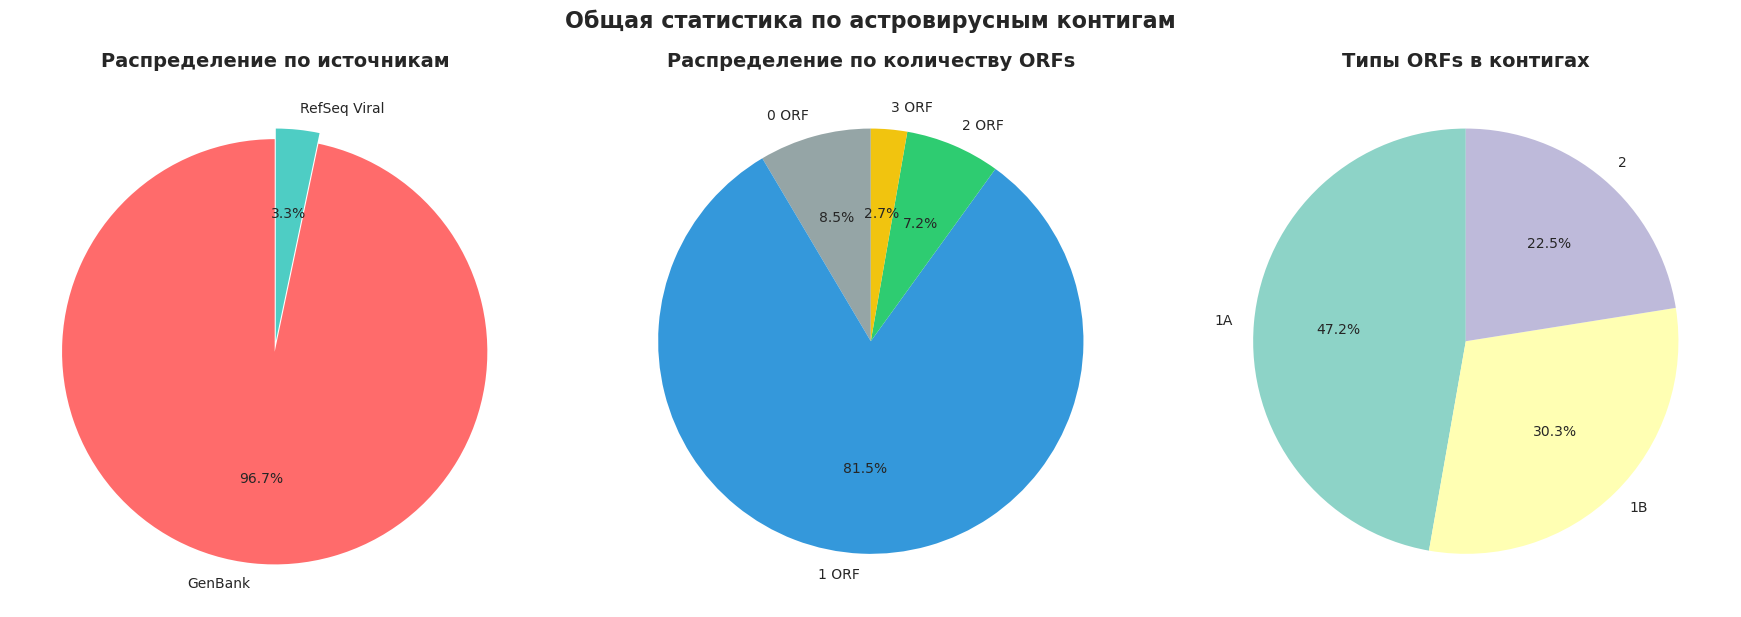

In [74]:
# 1. Общая статистика - круговые диаграммы
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1.1 Распределение по источникам (RefSeq vs GenBank)
source_counts = astro_df['source'].value_counts()
colors_source = ['#FF6B6B', '#4ECDC4']
axes[0].pie(source_counts.values, labels=source_counts.index, autopct='%1.1f%%', 
            colors=colors_source, startangle=90, explode=(0.05, 0))
axes[0].set_title('Распределение по источникам', fontsize=14, fontweight='bold')
axes[0].set_ylabel('')

# 1.2 Распределение по количеству ORFs
orf_count_dist = astro_df['orf_count_from_top5'].value_counts().sort_index()
colors_orfs = ['#95A5A6', '#3498DB', '#2ECC71', '#F1C40F']
axes[1].pie(orf_count_dist.values, labels=[f'{i} ORF' for i in orf_count_dist.index], 
            autopct='%1.1f%%', colors=colors_orfs[:len(orf_count_dist)], startangle=90)
axes[1].set_title('Распределение по количеству ORFs', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

# 1.3 Типы ORFs
all_orf_types = []
for orf_set in astro_df['orf_types_from_top5']:
    all_orf_types.extend(orf_set)
orf_type_counts = Counter(all_orf_types)

# Сортируем по убыванию
orf_types_sorted = dict(sorted(orf_type_counts.items(), key=lambda x: x[1], reverse=True))
colors_types = sns.color_palette("Set3", len(orf_types_sorted))

axes[2].pie(orf_types_sorted.values(), labels=orf_types_sorted.keys(), 
            autopct='%1.1f%%', colors=colors_types, startangle=90)
axes[2].set_title('Типы ORFs в контигах', fontsize=14, fontweight='bold')
axes[2].set_ylabel('')

plt.suptitle('Общая статистика по астровирусным контигам', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

D:\Users\User\AppData\Local\Temp\ipykernel_8800\3496601639.py:55: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax4.boxplot(data_to_plot, labels=[f'{i} ORF' for i in sorted(astro_df['orf_count_from_top5'].unique())],


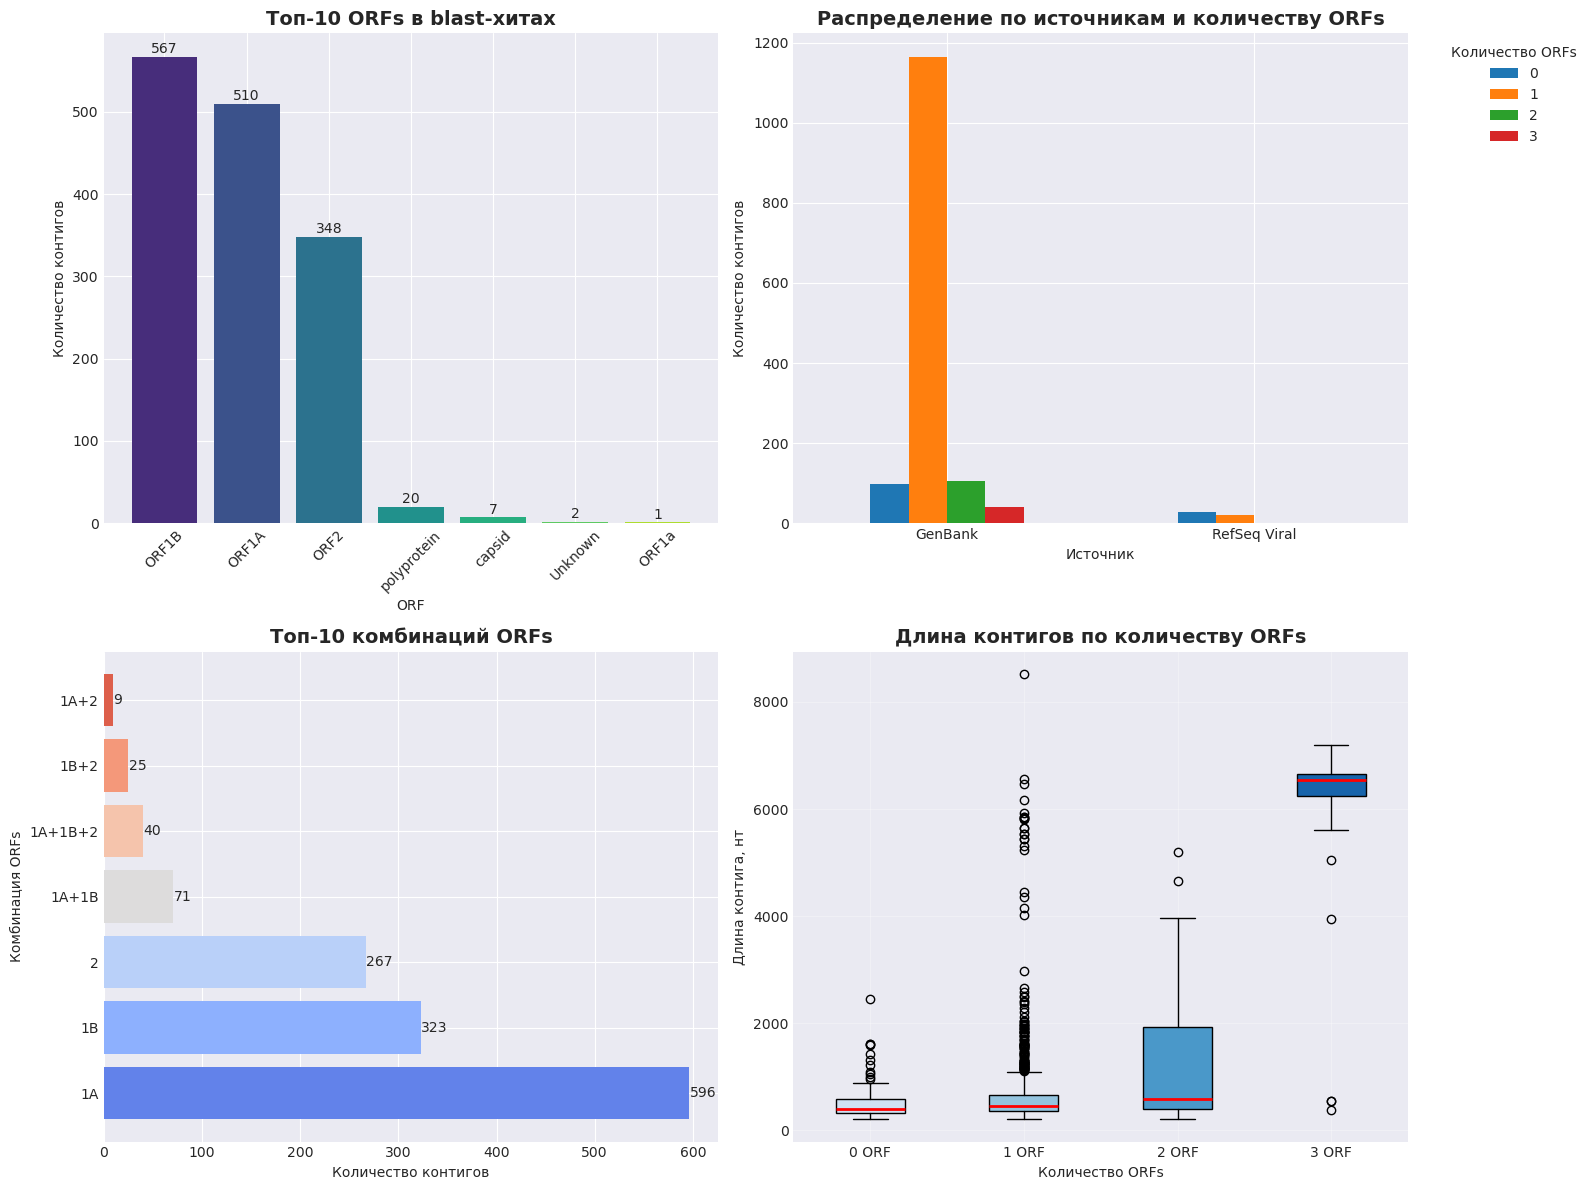

In [76]:
# 2. Барчарты с детальной статистикой
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 2.1 Количество контигов по ORFs (топ-10)
orf_counts = astro_df['orf'].value_counts().head(10)
ax1 = axes[0, 0]
bars1 = ax1.bar(orf_counts.index, orf_counts.values, color=sns.color_palette("viridis", len(orf_counts)))
ax1.set_title('Топ-10 ORFs в blast-хитах', fontsize=14, fontweight='bold')
ax1.set_xlabel('ORF')
ax1.set_ylabel('Количество контигов')
ax1.tick_params(axis='x', rotation=45)
# Добавляем значения на столбцы
for bar, val in zip(bars1, orf_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             str(val), ha='center', va='bottom', fontsize=10)

# 2.2 Количество контигов по источникам с детализацией по ORFs
source_orf = pd.crosstab(astro_df['source'], astro_df['orf_count_from_top5'])
ax2 = axes[0, 1]
source_orf.plot(kind='bar', ax=ax2)
ax2.set_title('Распределение по источникам и количеству ORFs', fontsize=14, fontweight='bold')
ax2.set_xlabel('Источник')
ax2.set_ylabel('Количество контигов')
ax2.legend(title='Количество ORFs', bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.tick_params(axis='x', rotation=0)

# 2.3 Комбинации ORFs (топ-10)
combo_counts = defaultdict(int)
for orf_set in astro_df['orf_types_from_top5']:
    if orf_set:
        combo = tuple(sorted(orf_set))
        combo_counts[combo] += 1

top_combos = dict(sorted(combo_counts.items(), key=lambda x: x[1], reverse=True)[:10])
combo_labels = ['+'.join(c) for c in top_combos.keys()]
combo_values = list(top_combos.values())

ax3 = axes[1, 0]
bars3 = ax3.barh(combo_labels, combo_values, color=sns.color_palette("coolwarm", len(combo_labels)))
ax3.set_title('Топ-10 комбинаций ORFs', fontsize=14, fontweight='bold')
ax3.set_xlabel('Количество контигов')
ax3.set_ylabel('Комбинация ORFs')
# Добавляем значения на столбцы
for bar, val in zip(bars3, combo_values):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
             str(val), ha='left', va='center', fontsize=10)

# 2.4 Длина контигов по количеству ORFs
complete_genomes = astro_df[astro_df['orf_count_from_top5'] >= 2]
incomplete_genomes = astro_df[astro_df['orf_count_from_top5'] == 1]

# Создаем boxplot
data_to_plot = [astro_df[astro_df['orf_count_from_top5'] == i]['Длина контига, нт'] for i in sorted(astro_df['orf_count_from_top5'].unique())]
ax4 = axes[1, 1]
bp = ax4.boxplot(data_to_plot, labels=[f'{i} ORF' for i in sorted(astro_df['orf_count_from_top5'].unique())], 
                 patch_artist=True, medianprops=dict(linewidth=2, color='red'))

# Раскрашиваем боксплоты
colors_box = sns.color_palette("Blues", len(data_to_plot))
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)

ax4.set_title('Длина контигов по количеству ORFs', fontsize=14, fontweight='bold')
ax4.set_xlabel('Количество ORFs')
ax4.set_ylabel('Длина контига, нт')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [77]:
# 3. Анализ полных геномов
print("\n" + "=" * 80)
print("ДЕТАЛЬНЫЙ АНАЛИЗ ПОЛНЫХ/ПОЧТИ ПОЛНЫХ ГЕНОМОВ")
print("=" * 80)

complete_genomes = astro_df[astro_df['orf_count_from_top5'] >= 2]
print(f"\nВсего контигов с 2-3 ORFs: {len(complete_genomes)}")
print(f"Из них с 2 ORFs: {len(complete_genomes[complete_genomes['orf_count_from_top5'] == 2])}")
print(f"Из них с 3 ORFs: {len(complete_genomes[complete_genomes['orf_count_from_top5'] == 3])}")

# Анализ по источникам для полных геномов
complete_by_source = complete_genomes['source'].value_counts()
print("\nРаспределение полных геномов по источникам:")
for source, count in complete_by_source.items():
    print(f"  {source}: {count} ({count/len(complete_genomes)*100:.2f}%)")

# Анализ по ORF комбинациям для полных геномов
complete_combos = defaultdict(int)
for orf_set in complete_genomes['orf_types_from_top5']:
    if orf_set:
        combo = tuple(sorted(orf_set))
        complete_combos[combo] += 1

print("\nКомбинации ORFs в полных геномах:")
for combo, count in sorted(complete_combos.items(), key=lambda x: x[1], reverse=True):
    combo_str = ', '.join(combo)
    print(f"  {combo_str}: {count} ({count/len(complete_genomes)*100:.2f}%)")


ДЕТАЛЬНЫЙ АНАЛИЗ ПОЛНЫХ/ПОЧТИ ПОЛНЫХ ГЕНОМОВ

Всего контигов с 2-3 ORFs: 145
Из них с 2 ORFs: 105
Из них с 3 ORFs: 40

Распределение полных геномов по источникам:
  GenBank: 145 (100.00%)

Комбинации ORFs в полных геномах:
  1A, 1B: 71 (48.97%)
  1A, 1B, 2: 40 (27.59%)
  1B, 2: 25 (17.24%)
  1A, 2: 9 (6.21%)



АНАЛИЗ ПО ХОЗЯЕВАМ

Топ-10 хозяев для астровирусов:
  Rhinolophus affinis: 496 (34.09%)
  viral metagenome: 294 (20.21%)
  Rousettus aegyptiacus: 80 (5.50%)
  Coleura afra: 58 (3.99%)
  Miniopterus sp. clade 10 TD-2020: 56 (3.85%)
  Cardioderma cor: 48 (3.30%)
  Myotis daubentonii: 45 (3.09%)
  Myotis_chinensis: 40 (2.75%)
  Miniopterus sp. clade 1 TD-2020: 36 (2.47%)
  bat gut metagenome: 34 (2.34%)


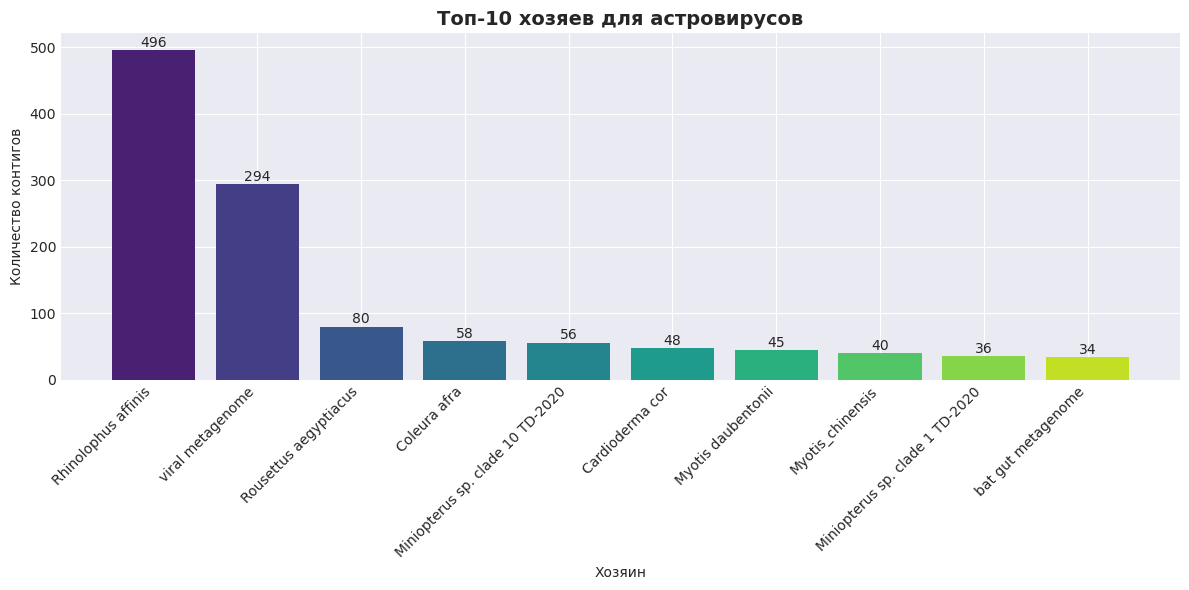

In [82]:
# 6. Статистика по хозяевам (если есть данные)
print("\n" + "=" * 80)
print("АНАЛИЗ ПО ХОЗЯЕВАМ")
print("=" * 80)

if 'Хозяин' in astro_df.columns:
    host_counts = astro_df['Хозяин'].value_counts().head(10)
    print("\nТоп-10 хозяев для астровирусов:")
    for host, count in host_counts.items():
        print(f"  {host}: {count} ({count/len(astro_df)*100:.2f}%)")
    
    # Визуализация
    if len(host_counts) > 0:
        plt.figure(figsize=(12, 6))
        bars = plt.bar(host_counts.index, host_counts.values, color=sns.color_palette("viridis", len(host_counts)))
        plt.title('Топ-10 хозяев для астровирусов', fontsize=14, fontweight='bold')
        plt.xlabel('Хозяин')
        plt.ylabel('Количество контигов')
        plt.xticks(rotation=45, ha='right')
        
        # Добавляем значения
        for bar, val in zip(bars, host_counts.values):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                    str(val), ha='center', va='bottom', fontsize=10)
        
        plt.tight_layout()
        plt.show()
else:
    print("Нет данных о хозяевах в текущем файле")

In [83]:
# 7. Итоговый отчет с примерами
print("\n" + "=" * 80)
print("ИТОГОВЫЙ ОТЧЕТ ПО АНАЛИЗУ АСТРОВИРУСОВ")
print("=" * 80)

print("\n1. ОБЩАЯ СТАТИСТИКА:")
print(f"   - Всего записей в файле: {len(df_1)}")
print(f"   - Записей, относящихся к астровирусам: {len(astro_df)}")
print(f"   - Уникальных образцов с астровирусами: {astro_df['Образец'].nunique()}")

print("\n2. ИСТОЧНИКИ:")
for source, count in source_counts.items():
    print(f"   - {source}: {count} ({count/len(astro_df)*100:.2f}%)")

print("\n3. РАСПРЕДЕЛЕНИЕ ПО ORFs (из топ-5 профилей):")
for count in sorted(orf_count_dist.index):
    num = orf_count_dist[count]
    print(f"   - {count} ORF: {num} контигов ({num/len(astro_df)*100:.2f}%)")

print("\n4. ТИПЫ ORFs:")
for orf_type, count in orf_type_counts.most_common():
    print(f"   - {orf_type}: {count} ({count/len(astro_df)*100:.2f}%)")

print("\n5. ПОЛНЫЕ/ПОЧТИ ПОЛНЫЕ ГЕНОМЫ:")
print(f"   - Контигов с 2-3 ORFs: {len(complete_genomes)}")
print(f"   - Процент от всех астровирусных контигов: {len(complete_genomes)/len(astro_df)*100:.2f}%")
print(f"   - Уникальных образцов с полными геномами: {complete_genomes['Образец'].nunique()}")

print("\n6. ТОП-5 КОМБИНАЦИЙ ORFs:")
for combo, count in sorted(combo_counts.items(), key=lambda x: x[1], reverse=True)[:5]:
    combo_str = ', '.join(combo)
    print(f"   - {combo_str}: {count} контигов ({count/len(astro_df)*100:.2f}%)")

print("\n7. ПРИМЕРЫ ПОЛНЫХ ГЕНОМОВ:")
if len(complete_genomes) > 0:
    for i, (_, row) in enumerate(complete_genomes.head(5).iterrows(), 1):
        print(f"\n   Пример {i}:")
        print(f"   - Образец: {row['Образец']}")
        print(f"   - Длина: {row['Длина контига, нт']} нт")
        print(f"   - ORFs: {', '.join(sorted(row['orf_types_from_top5']))}")
        print(f"   - Топ-5: {row['Топ 5 профилей'][:100]}...")
else:
    print("   Нет полных геномов в данных")

print("\n" + "=" * 80)
print("АНАЛИЗ ЗАВЕРШЕН")
print("=" * 80)


ИТОГОВЫЙ ОТЧЕТ ПО АНАЛИЗУ АСТРОВИРУСОВ

1. ОБЩАЯ СТАТИСТИКА:
   - Всего записей в файле: 143505
   - Записей, относящихся к астровирусам: 1455
   - Уникальных образцов с астровирусами: 210

2. ИСТОЧНИКИ:
   - GenBank: 1407 (96.70%)
   - RefSeq Viral: 48 (3.30%)

3. РАСПРЕДЕЛЕНИЕ ПО ORFs (из топ-5 профилей):
   - 0 ORF: 124 контигов (8.52%)
   - 1 ORF: 1186 контигов (81.51%)
   - 2 ORF: 105 контигов (7.22%)
   - 3 ORF: 40 контигов (2.75%)

4. ТИПЫ ORFs:
   - 1A: 716 (49.21%)
   - 1B: 459 (31.55%)
   - 2: 341 (23.44%)

5. ПОЛНЫЕ/ПОЧТИ ПОЛНЫЕ ГЕНОМЫ:
   - Контигов с 2-3 ORFs: 145
   - Процент от всех астровирусных контигов: 9.97%
   - Уникальных образцов с полными геномами: 69

6. ТОП-5 КОМБИНАЦИЙ ORFs:
   - 1A: 596 контигов (40.96%)
   - 1B: 323 контигов (22.20%)
   - 2: 267 контигов (18.35%)
   - 1A, 1B: 71 контигов (4.88%)
   - 1A, 1B, 2: 40 контигов (2.75%)

7. ПРИМЕРЫ ПОЛНЫХ ГЕНОМОВ:

   Пример 1:
   - Образец: ERR3179235
   - Длина: 423 нт
   - ORFs: 1A, 2
   - Топ-5: Astroviridae 

In [84]:
# Сохранение 40 контигов с полными геномами в Excel
print("=" * 80)
print("СОХРАНЕНИЕ 40 КОНТИГОВ С ПОЛНЫМИ ГЕНОМАМИ")
print("=" * 80)

# Получаем контиги с полными геномами (2-3 ORFs)
complete_genomes = astro_df[astro_df['orf_count_from_top5'] >= 2].copy()

print(f"\nВсего контигов с полными геномами: {len(complete_genomes)}")

# Берем первые 40 (или все, если меньше 40)
if len(complete_genomes) > 40:
    complete_genomes_40 = complete_genomes.head(40)
    print(f"Выбрано 40 контигов для сохранения")
else:
    complete_genomes_40 = complete_genomes
    print(f"Выбрано все {len(complete_genomes)} контигов для сохранения")

# Выбираем нужные колонки для сохранения
columns_to_keep = [
    'Образец',
    'Страна',
    'Год',
    'Хозяин',
    'Длина контига, нт',
    'Профиль',
    'Идентичность, %',
    'Длина выравнивания, амк',
    'Мисматчи, амк',
    'Начало контига',
    'Конец контига',
    'Начало референса',
    'Конец референса',
    'Длина референса, амк',
    'Покрытие контига, %',
    'Покрытие референса, %',
    'E-value',
    'Bit-score',
    'Бласт хит',
    'Инфо',
    'Источник',
    'Топ 5 профилей',
    'orf_count_from_top5',
    'orf_types_from_top5'
]

# Проверяем, какие колонки есть в данных
available_columns = [col for col in columns_to_keep if col in complete_genomes_40.columns]
print(f"\nДоступные колонки для сохранения: {len(available_columns)} из {len(columns_to_keep)}")

# Создаем финальный DataFrame
complete_genomes_export = complete_genomes_40[available_columns].copy()

# Добавляем колонку с типом ORFs в читаемом формате
complete_genomes_export['ORF типы'] = complete_genomes_export['orf_types_from_top5'].apply(
    lambda x: ', '.join(sorted(x)) if x else 'Unknown'
)

# Добавляем колонку с количеством ORFs
complete_genomes_export['Количество ORFs'] = complete_genomes_export['orf_count_from_top5']

# Сортируем по количеству ORFs (сначала 3, потом 2) и по длине контига
complete_genomes_export = complete_genomes_export.sort_values(
    ['orf_count_from_top5', 'Длина контига, нт'], 
    ascending=[False, False]
)

# Сохраняем в Excel
output_excel = 'complete_genomes_40.xlsx'
try:
    with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
        # Сохраняем основную таблицу
        complete_genomes_export.to_excel(writer, sheet_name='Полные геномы', index=False)
        
        # Добавляем лист со статистикой
        stats_data = {
            'Параметр': [
                'Всего контигов с полными геномами',
                'Выбрано для экспорта',
                'Контигов с 2 ORFs',
                'Контигов с 3 ORFs',
                'Средняя длина контига',
                'Медианная длина контига',
                'Минимальная длина',
                'Максимальная длина'
            ],
            'Значение': [
                len(complete_genomes),
                len(complete_genomes_export),
                len(complete_genomes_export[complete_genomes_export['orf_count_from_top5'] == 2]),
                len(complete_genomes_export[complete_genomes_export['orf_count_from_top5'] == 3]),
                f"{complete_genomes_export['Длина контига, нт'].mean():.0f}",
                f"{complete_genomes_export['Длина контига, нт'].median():.0f}",
                complete_genomes_export['Длина контига, нт'].min(),
                complete_genomes_export['Длина контига, нт'].max()
            ]
        }
        stats_df = pd.DataFrame(stats_data)
        stats_df.to_excel(writer, sheet_name='Статистика', index=False)
        
        # Добавляем лист с комбинациями ORFs
        combo_counts = complete_genomes_export['ORF типы'].value_counts().reset_index()
        combo_counts.columns = ['Комбинация ORFs', 'Количество']
        combo_counts.to_excel(writer, sheet_name='Комбинации ORFs', index=False)
        
    print(f"\nФайл успешно сохранен: {output_excel}")
    print(f"Количество строк: {len(complete_genomes_export)}")
    
except Exception as e:
    print(f"Ошибка при сохранении Excel файла: {e}")
    print("Попробуем сохранить в CSV...")
    
    # Если Excel не получается, сохраняем в CSV
    output_csv = 'complete_genomes_40.csv'
    complete_genomes_export.to_csv(output_csv, sep='\t', index=False, encoding='utf-8-sig')
    print(f"Файл сохранен в формате CSV: {output_csv}")

СОХРАНЕНИЕ 40 КОНТИГОВ С ПОЛНЫМИ ГЕНОМАМИ

Всего контигов с полными геномами: 145
Выбрано 40 контигов для сохранения

Доступные колонки для сохранения: 23 из 24

Файл успешно сохранен: complete_genomes_40.xlsx
Количество строк: 40


In [85]:
# Показываем первые строки сохраненной таблицы
print("\n" + "=" * 80)
print("ПРИМЕР СОХРАНЕННЫХ ДАННЫХ (первые 5 строк)")
print("=" * 80)

# Выводим основные колонки для просмотра
display_columns = ['Образец', 'Длина контига, нт', 'ORF типы', 'Количество ORFs', 'Топ 5 профилей']
if all(col in complete_genomes_export.columns for col in display_columns):
    print(complete_genomes_export[display_columns].head(5).to_string(index=False))
else:
    print(complete_genomes_export.head(5).to_string(index=False))


ПРИМЕР СОХРАНЕННЫХ ДАННЫХ (первые 5 строк)
    Образец  Длина контига, нт  ORF типы  Количество ORFs                                                                                                                                    Топ 5 профилей
SRR22936710               7189 1A, 1B, 2                3 Astroviridae 1A (52.93); Astroviridae 1B (52.49); Astroviridae 2 (46.59); Astroviridae capsid;VP90 (37.90); Mamastrovirus polyprotein 1ab (30.34)
SRR22936808               6881 1A, 1B, 2                3 Astroviridae 1B (53.87); Astroviridae 1A (52.33); Astroviridae 2 (47.07); Astroviridae capsid;VP90 (37.04); Mamastrovirus polyprotein 1ab (31.44)
 ERR3179770               6725 1A, 1B, 2                3 Astroviridae 1A (54.51); Astroviridae 1B (52.81); Astroviridae 2 (46.35); Astroviridae capsid;VP90 (37.60); Mamastrovirus polyprotein 1ab (30.32)
 ERR3179775               6662 1A, 1B, 2                3 Astroviridae 1A (54.20); Astroviridae 1B (52.81); Astroviridae 2 (46.36); Astrovir

In [87]:
# Проверка реального распределения комбинаций ORFs
print("=" * 80)
print("РЕАЛЬНОЕ РАСПРЕДЕЛЕНИЕ КОМБИНАЦИЙ ORFs")
print("=" * 80)

# Подсчет всех комбинаций
orf_combinations = defaultdict(int)
for orf_set in astro_df['orf_types_from_top5']:
    if orf_set:
        combo = tuple(sorted(orf_set))
        orf_combinations[combo] += 1

# Выводим все комбинации с сортировкой по убыванию
print("\nВсе комбинации ORFs (отсортировано по убыванию):")
for combo, count in sorted(orf_combinations.items(), key=lambda x: x[1], reverse=True):
    combo_str = ', '.join(combo)
    print(f"  {combo_str}: {count} контигов")

# Специально проверяем комбинацию 1A, 1B, 2
combo_1a_1b_2 = ('1A', '1B', '2')
if combo_1a_1b_2 in orf_combinations:
    count_3orfs = orf_combinations[combo_1a_1b_2]
    print(f"\nКонтигов с комбинацией 1A, 1B, 2 (все 3 ORFs): {count_3orfs}")
else:
    print("\nКонтигов с комбинацией 1A, 1B, 2 (все 3 ORFs): 0")

# Проверяем комбинации с 2 ORFs
print("\nКомбинации с 2 ORFs:")
two_orfs = {combo: count for combo, count in orf_combinations.items() if len(combo) == 2}
for combo, count in sorted(two_orfs.items(), key=lambda x: x[1], reverse=True):
    combo_str = ', '.join(combo)
    print(f"  {combo_str}: {count} контигов")

# Проверяем комбинации с 1 ORF
print("\nКомбинации с 1 ORF:")
one_orf = {combo: count for combo, count in orf_combinations.items() if len(combo) == 1}
for combo, count in sorted(one_orf.items(), key=lambda x: x[1], reverse=True):
    combo_str = ', '.join(combo)
    print(f"  {combo_str}: {count} контигов")

РЕАЛЬНОЕ РАСПРЕДЕЛЕНИЕ КОМБИНАЦИЙ ORFs

Все комбинации ORFs (отсортировано по убыванию):
  1A: 596 контигов
  1B: 323 контигов
  2: 267 контигов
  1A, 1B: 71 контигов
  1A, 1B, 2: 40 контигов
  1B, 2: 25 контигов
  1A, 2: 9 контигов

Контигов с комбинацией 1A, 1B, 2 (все 3 ORFs): 40

Комбинации с 2 ORFs:
  1A, 1B: 71 контигов
  1B, 2: 25 контигов
  1A, 2: 9 контигов

Комбинации с 1 ORF:
  1A: 596 контигов
  1B: 323 контигов
  2: 267 контигов


In [88]:
# Показываем примеры контигов с 3 ORFs (1A+1B+2)
print("\n" + "=" * 80)
print("ПРИМЕРЫ КОНТИГОВ С 3 ORFs (1A, 1B, 2)")
print("=" * 80)

# Находим контиги с 3 ORFs
three_orfs_examples = astro_df[astro_df['orf_types_from_top5'] == {'1A', '1B', '2'}].copy()

print(f"\nНайдено контигов с 1A+1B+2: {len(three_orfs_examples)}")

if len(three_orfs_examples) > 0:
    print("\nПримеры таких контигов:")
    for i, (_, row) in enumerate(three_orfs_examples.head(10).iterrows(), 1):
        print(f"\n{i}. Образец: {row['Образец']}")
        print(f"   Длина: {row['Длина контига, нт']} нт")
        print(f"   ORFs: {', '.join(sorted(row['orf_types_from_top5']))}")
        print(f"   Топ-5: {row['Топ 5 профилей']}")
        print("-" * 60)
else:
    print("\nНет контигов с комбинацией 1A+1B+2")
    
# Показываем примеры с 2 ORFs (разные комбинации)
print("\n" + "=" * 80)
print("ПРИМЕРЫ КОНТИГОВ С 2 ORFs")
print("=" * 80)

two_orfs_examples = astro_df[astro_df['orf_count_from_top5'] == 2].copy()

# Группируем по комбинациям
for combo in sorted(set(tuple(sorted(x)) for x in two_orfs_examples['orf_types_from_top5'] if x)):
    combo_str = ', '.join(combo)
    count = len(two_orfs_examples[two_orfs_examples['orf_types_from_top5'] == set(combo)])
    print(f"\nКомбинация {combo_str} ({count} контигов):")
    
    # Показываем 3 примера
    examples = two_orfs_examples[two_orfs_examples['orf_types_from_top5'] == set(combo)].head(3)
    for _, row in examples.iterrows():
        print(f"  - {row['Образец']} (длина: {row['Длина контига, нт']} нт)")
        print(f"    Топ-5: {row['Топ 5 профилей'][:100]}...")


ПРИМЕРЫ КОНТИГОВ С 3 ORFs (1A, 1B, 2)

Найдено контигов с 1A+1B+2: 40

Примеры таких контигов:

1. Образец: ERR3179734
   Длина: 5995 нт
   ORFs: 1A, 1B, 2
   Топ-5: Astroviridae 1B (52.83); Astroviridae 1A (46.42); Astroviridae 2 (46.37); Astroviridae capsid;VP90 (37.62); Mamastrovirus polyprotein 1ab (30.34)
------------------------------------------------------------

2. Образец: ERR3179739
   Длина: 6612 нт
   ORFs: 1A, 1B, 2
   Топ-5: Astroviridae 1A (54.44); Astroviridae 1B (52.82); Astroviridae 2 (46.36); Astroviridae capsid;VP90 (37.63); Mamastrovirus polyprotein 1ab (30.33)
------------------------------------------------------------

3. Образец: ERR3179760
   Длина: 6390 нт
   ORFs: 1A, 1B, 2
   Топ-5: Astroviridae 1B (52.82); Astroviridae 1A (52.29); Astroviridae 2 (46.36); Astroviridae capsid;VP90 (37.62); Mamastrovirus polyprotein 1ab (30.33)
------------------------------------------------------------

4. Образец: ERR3179770
   Длина: 6725 нт
   ORFs: 1A, 1B, 2
   Топ-5: